# Evaluation & Interpretation: Telco Customer Churn

Notebook ini memuat FR-5 (Evaluasi & Interpretasi).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)
df = df.drop(columns=['customerID'])
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

## Jalankan Evaluation Script

Script `run_evaluation.py` menghitung metrik test set, confusion matrix, kurva ROC/PR, feature importance.

In [2]:
!python ../src/run_evaluation.py

Traceback (most recent call last):
  File "c:\Users\Carbon\telco-churn\src\run_evaluation.py", line 15, in <module>
    df = pd.read_csv("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Carbon\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\io\parsers\readers.py", line 1026, in read_csv
    return _read(filepath_or_buffer, kwds)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Carbon\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\io\parsers\readers.py", line 620, in _read
    parser = TextFileReader(filepath_or_buffer, **kwds)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Carbon\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-package

In [3]:
# Load metrics
with open("../reports/metrics.json", "r") as f:
    metrics = json.load(f)

print("TEST SET METRICS")
print(f"ROC-AUC: {metrics['ROC_AUC']:.4f}")
print(f"PR-AUC: {metrics['PR_AUC']:.4f}")
print(f"Recall (Churn): {metrics['Recall']:.4f}")
print(f"Precision (Churn): {metrics['Precision']:.4f}")
print(f"F1 (Churn): {metrics['F1']:.4f}")
print(f"Accuracy: {metrics['Accuracy']:.4f}")

TEST SET METRICS
ROC-AUC: 0.8415
PR-AUC: 0.6325
Recall (Churn): 0.7273
Precision (Churn): 0.5397
F1 (Churn): 0.6196
Accuracy: 0.7630


In [4]:
# Display top features from JSON
print("\nTOP 10 FEATURES")
for i, feat in enumerate(metrics['Feature_Importance_Top_10'], 1):
    print(f"{i}. {feat['feature']}: {feat['importance']:.4f}")


TOP 10 FEATURES
1. tenure: 0.0771
2. MonthlyCharges: 0.0338
3. InternetService: 0.0161
4. TotalCharges: 0.0077
5. Contract: 0.0043
6. OnlineSecurity: 0.0028
7. PaymentMethod: 0.0021
8. StreamingMovies: 0.0019
9. MultipleLines: 0.0013
10. StreamingTV: 0.0011



Confusion Matrix:


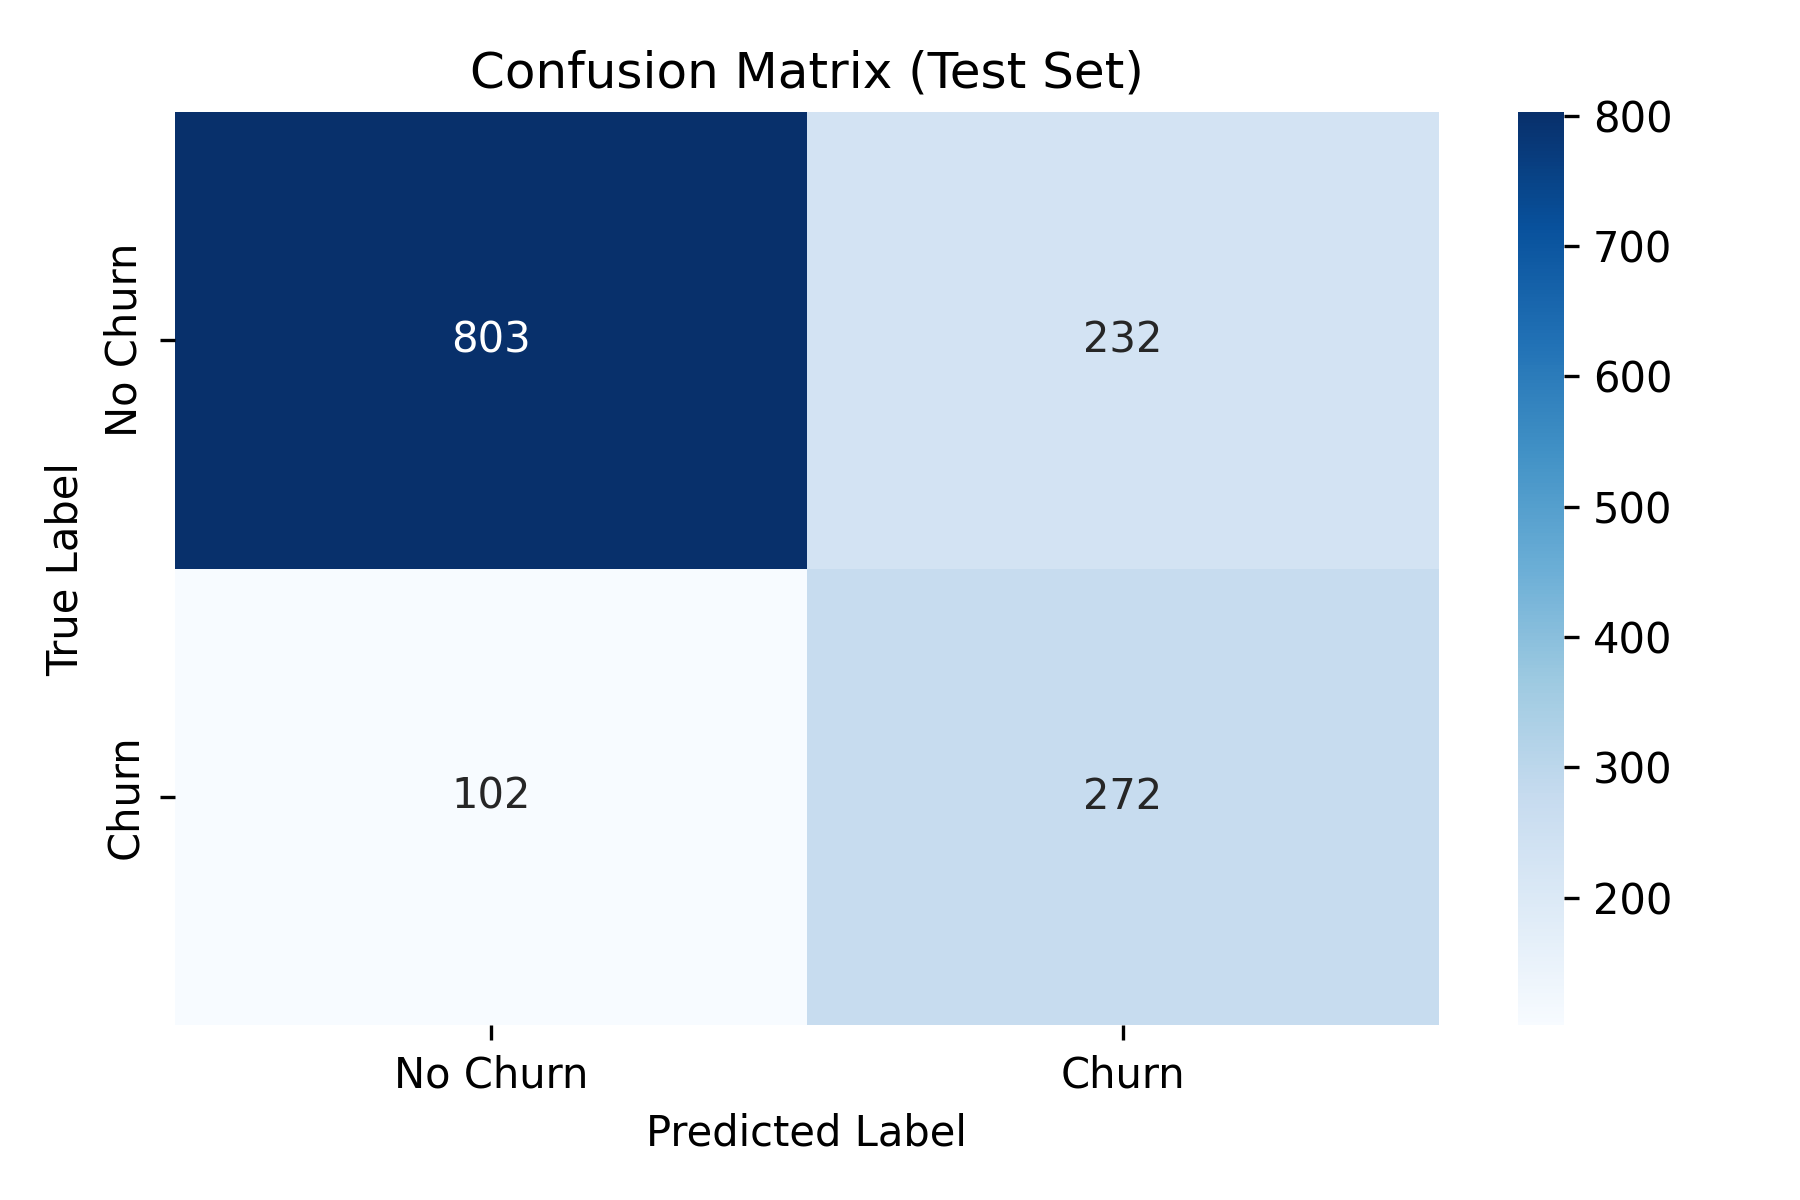

In [5]:
# Show figures
from IPython.display import Image
print("\nConfusion Matrix:")
Image(filename='../reports/figures/confusion_matrix.png')

ROC Curve:


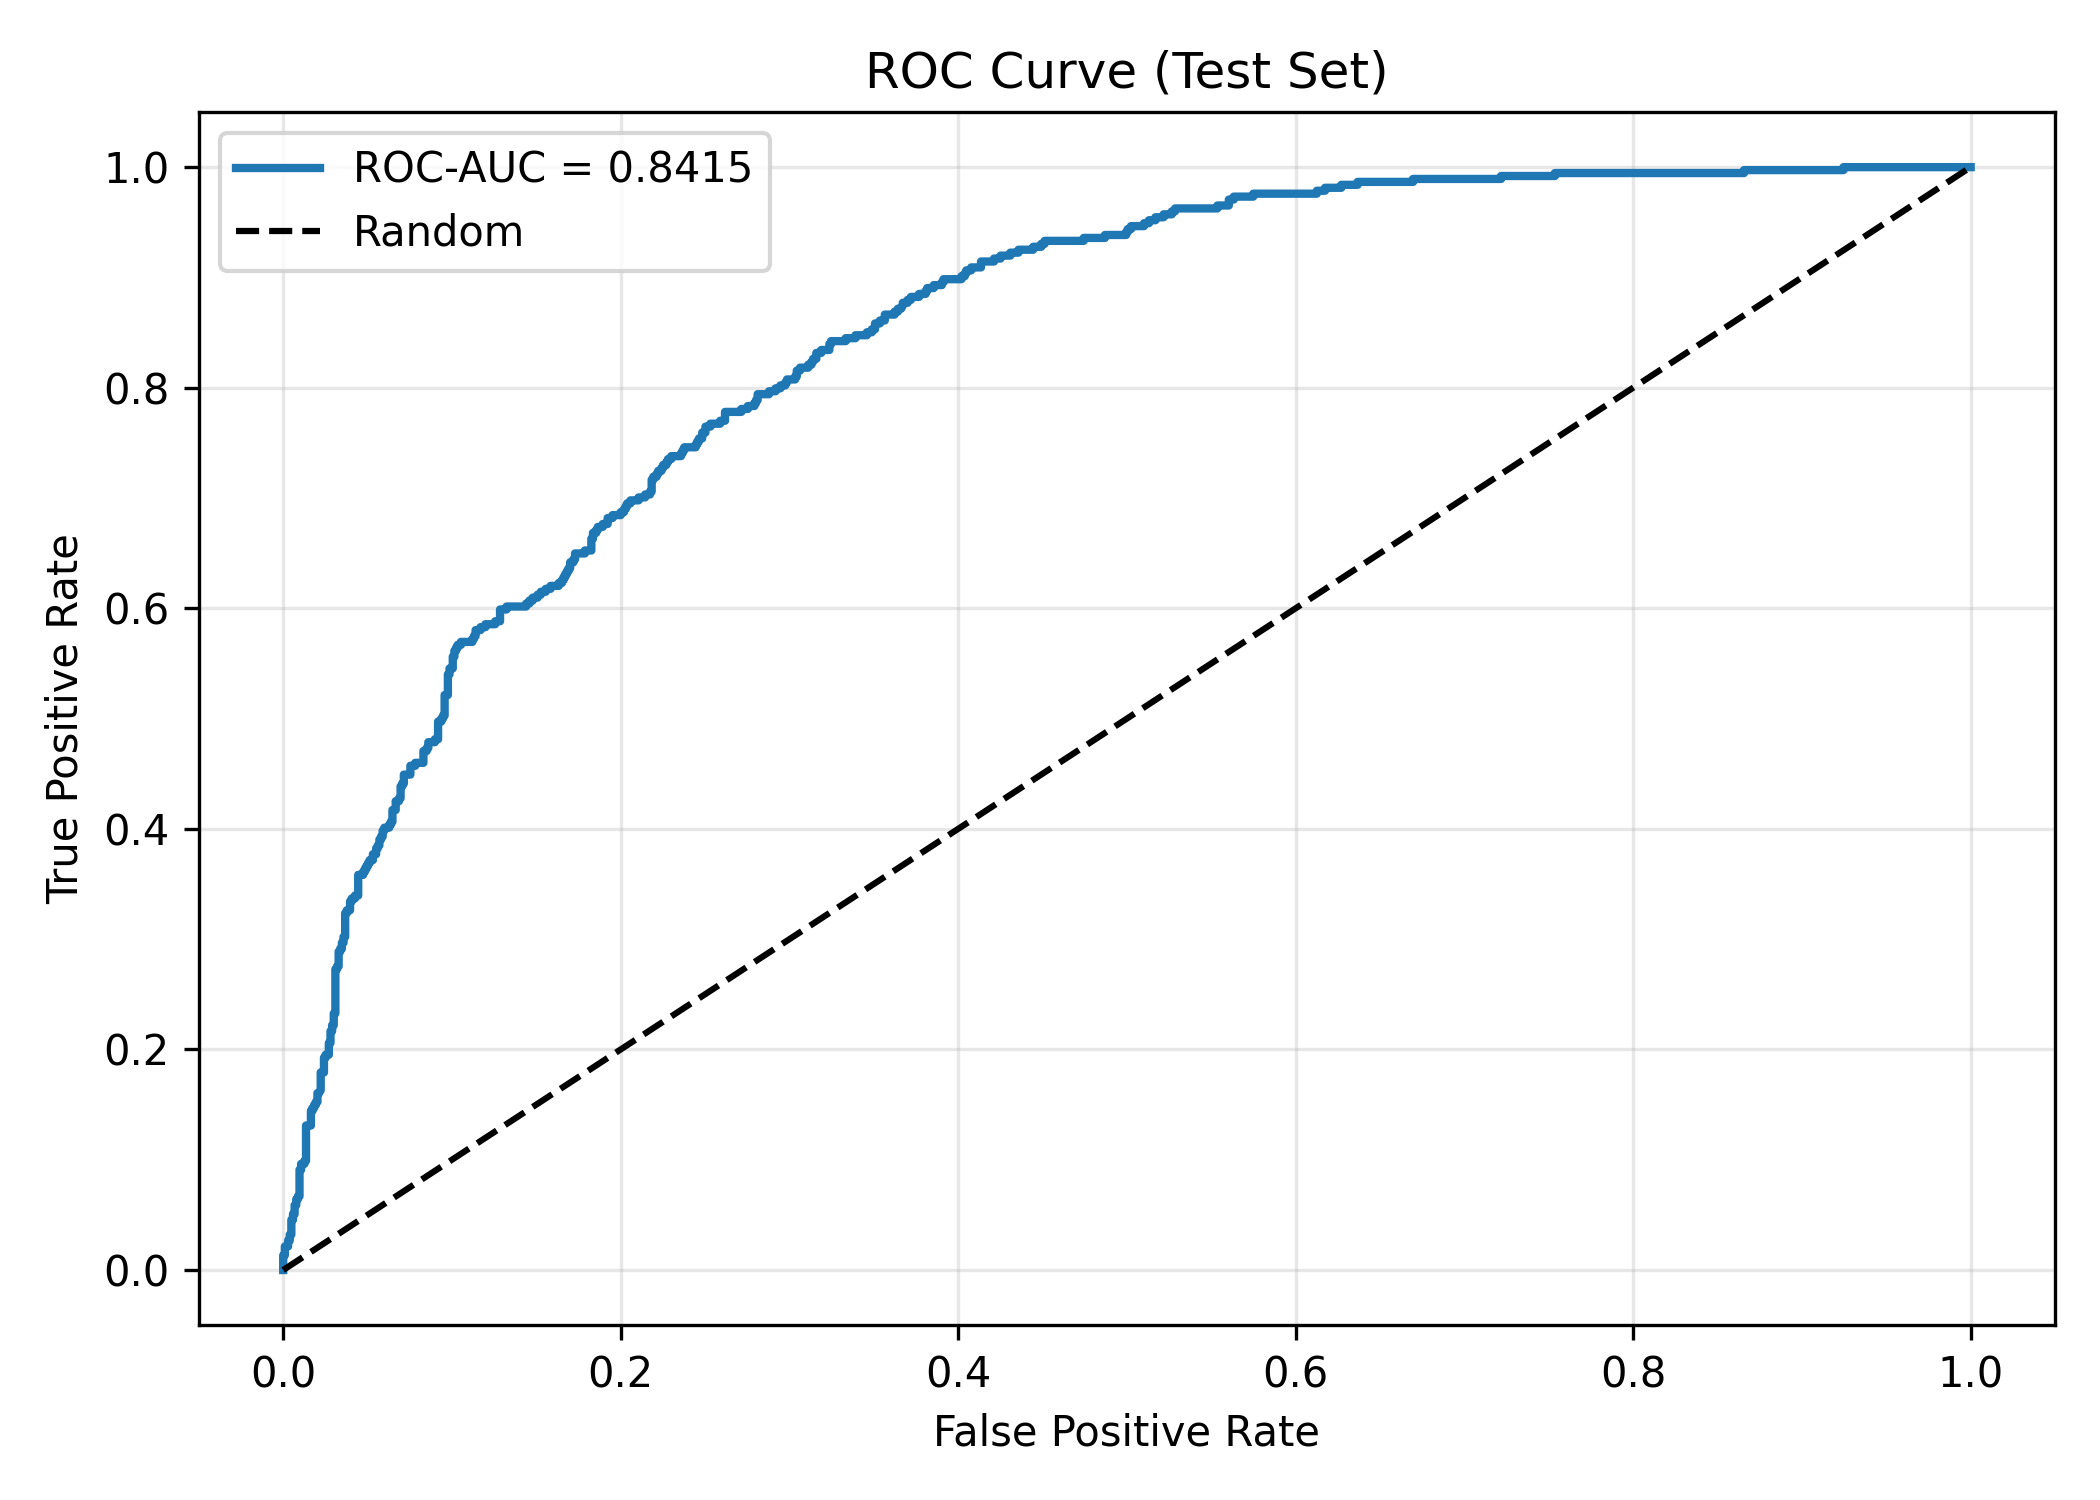

In [6]:
print("ROC Curve:")
Image(filename='../reports/figures/roc_curve.png')

Precision-Recall Curve:


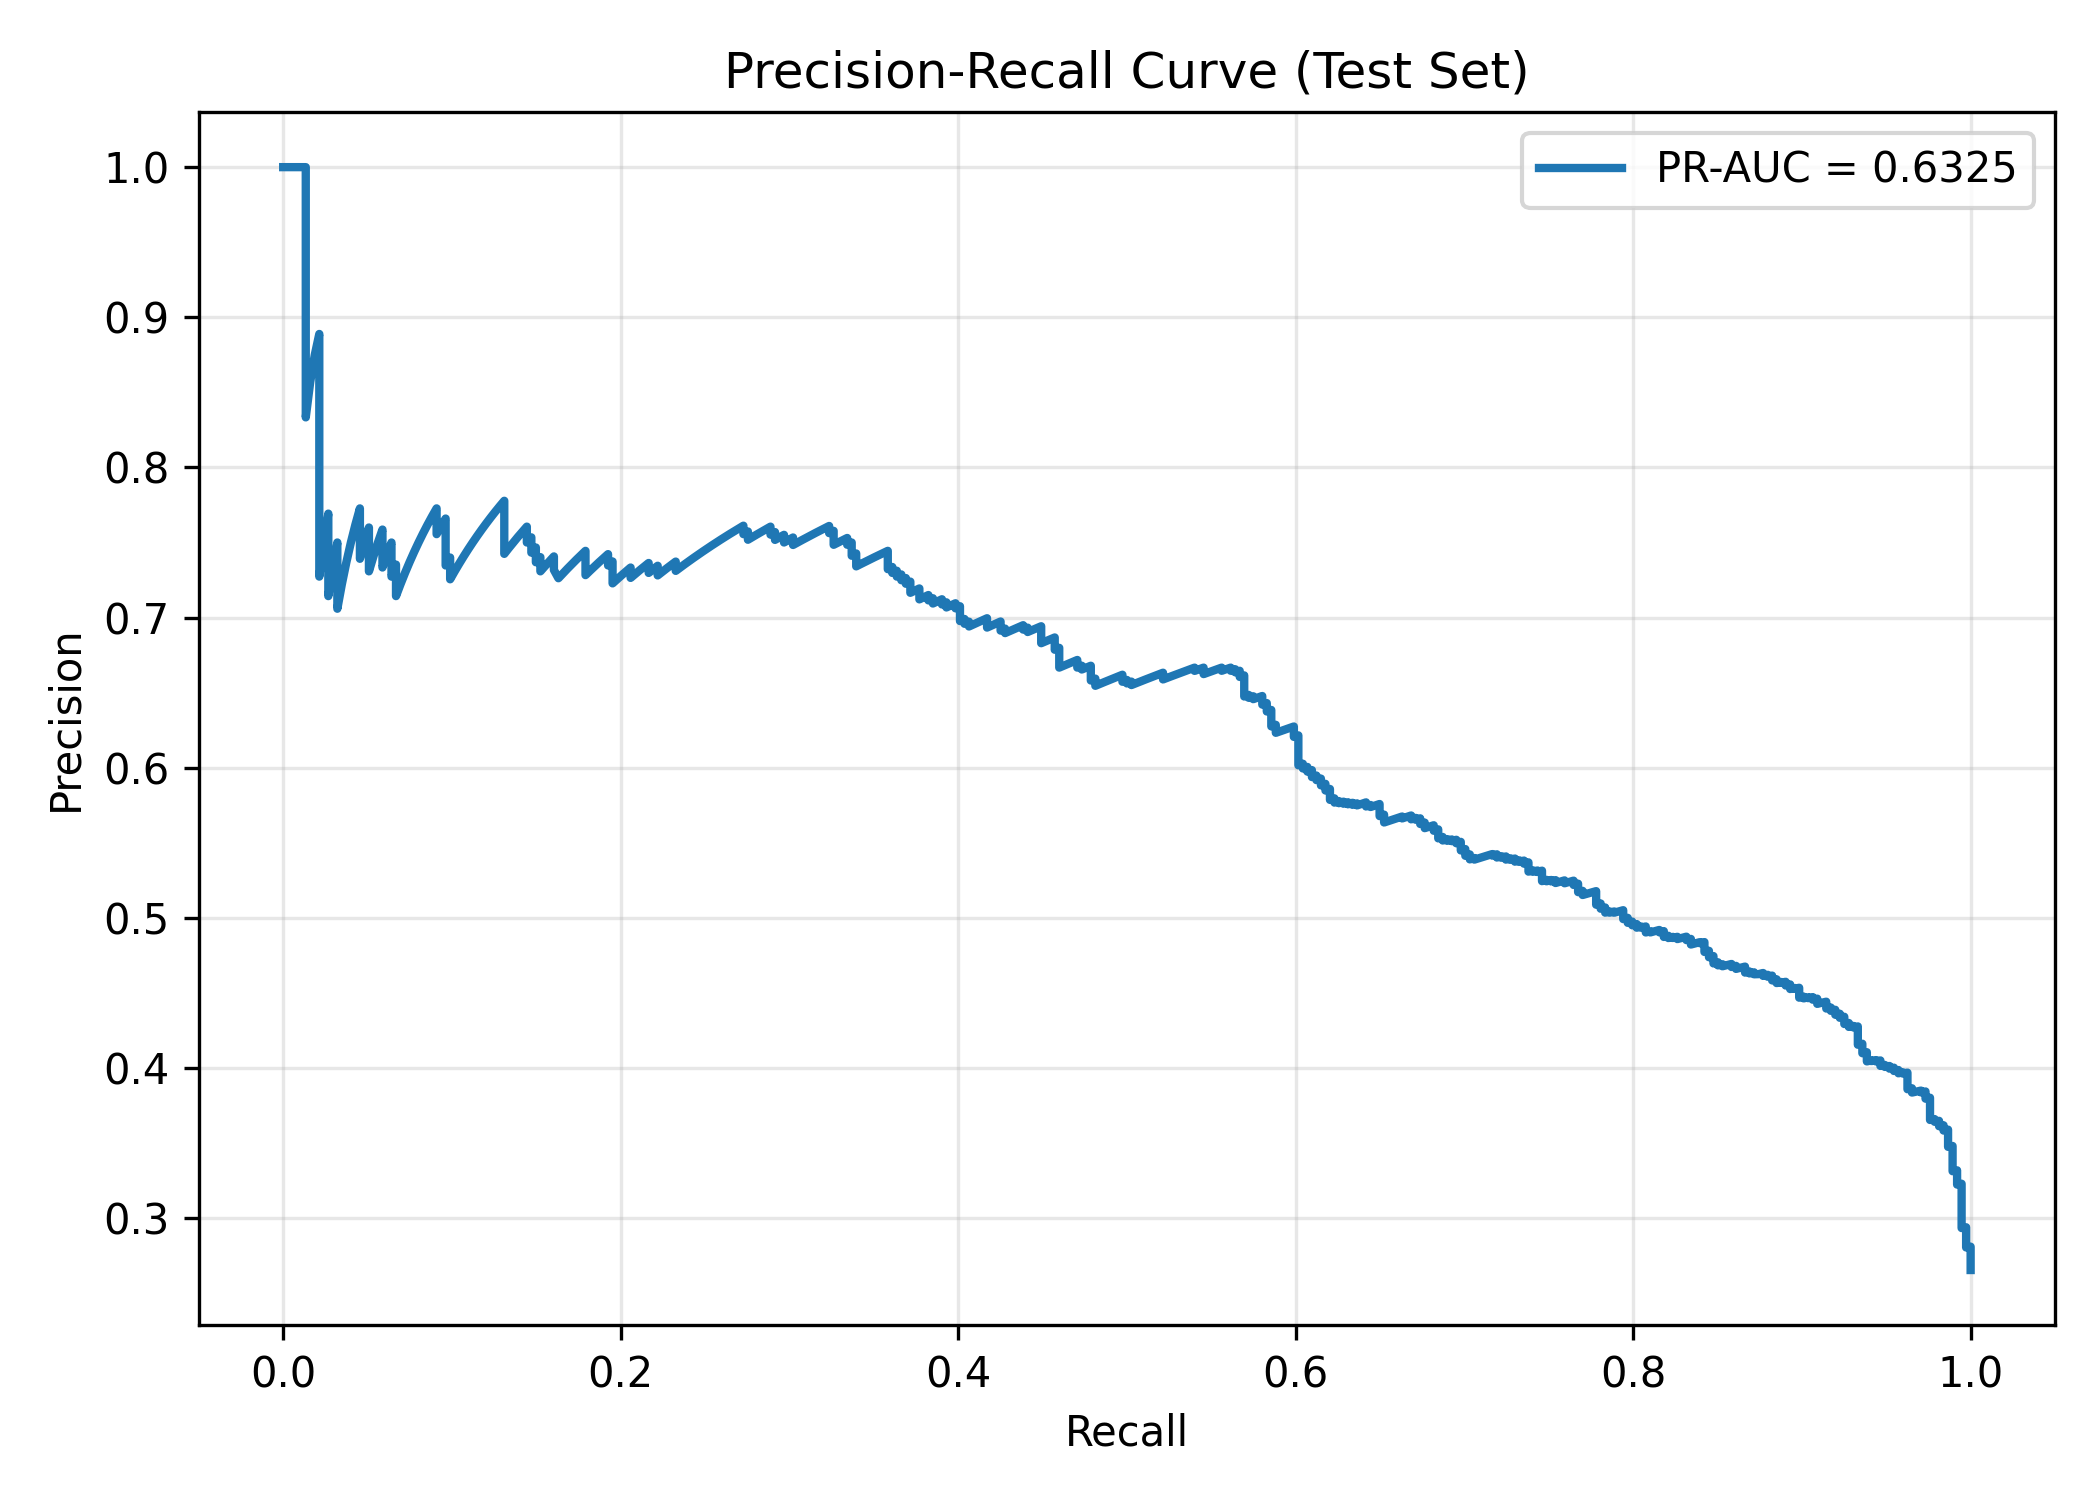

In [7]:
print("Precision-Recall Curve:")
Image(filename='../reports/figures/pr_curve.png')

Feature Importance:


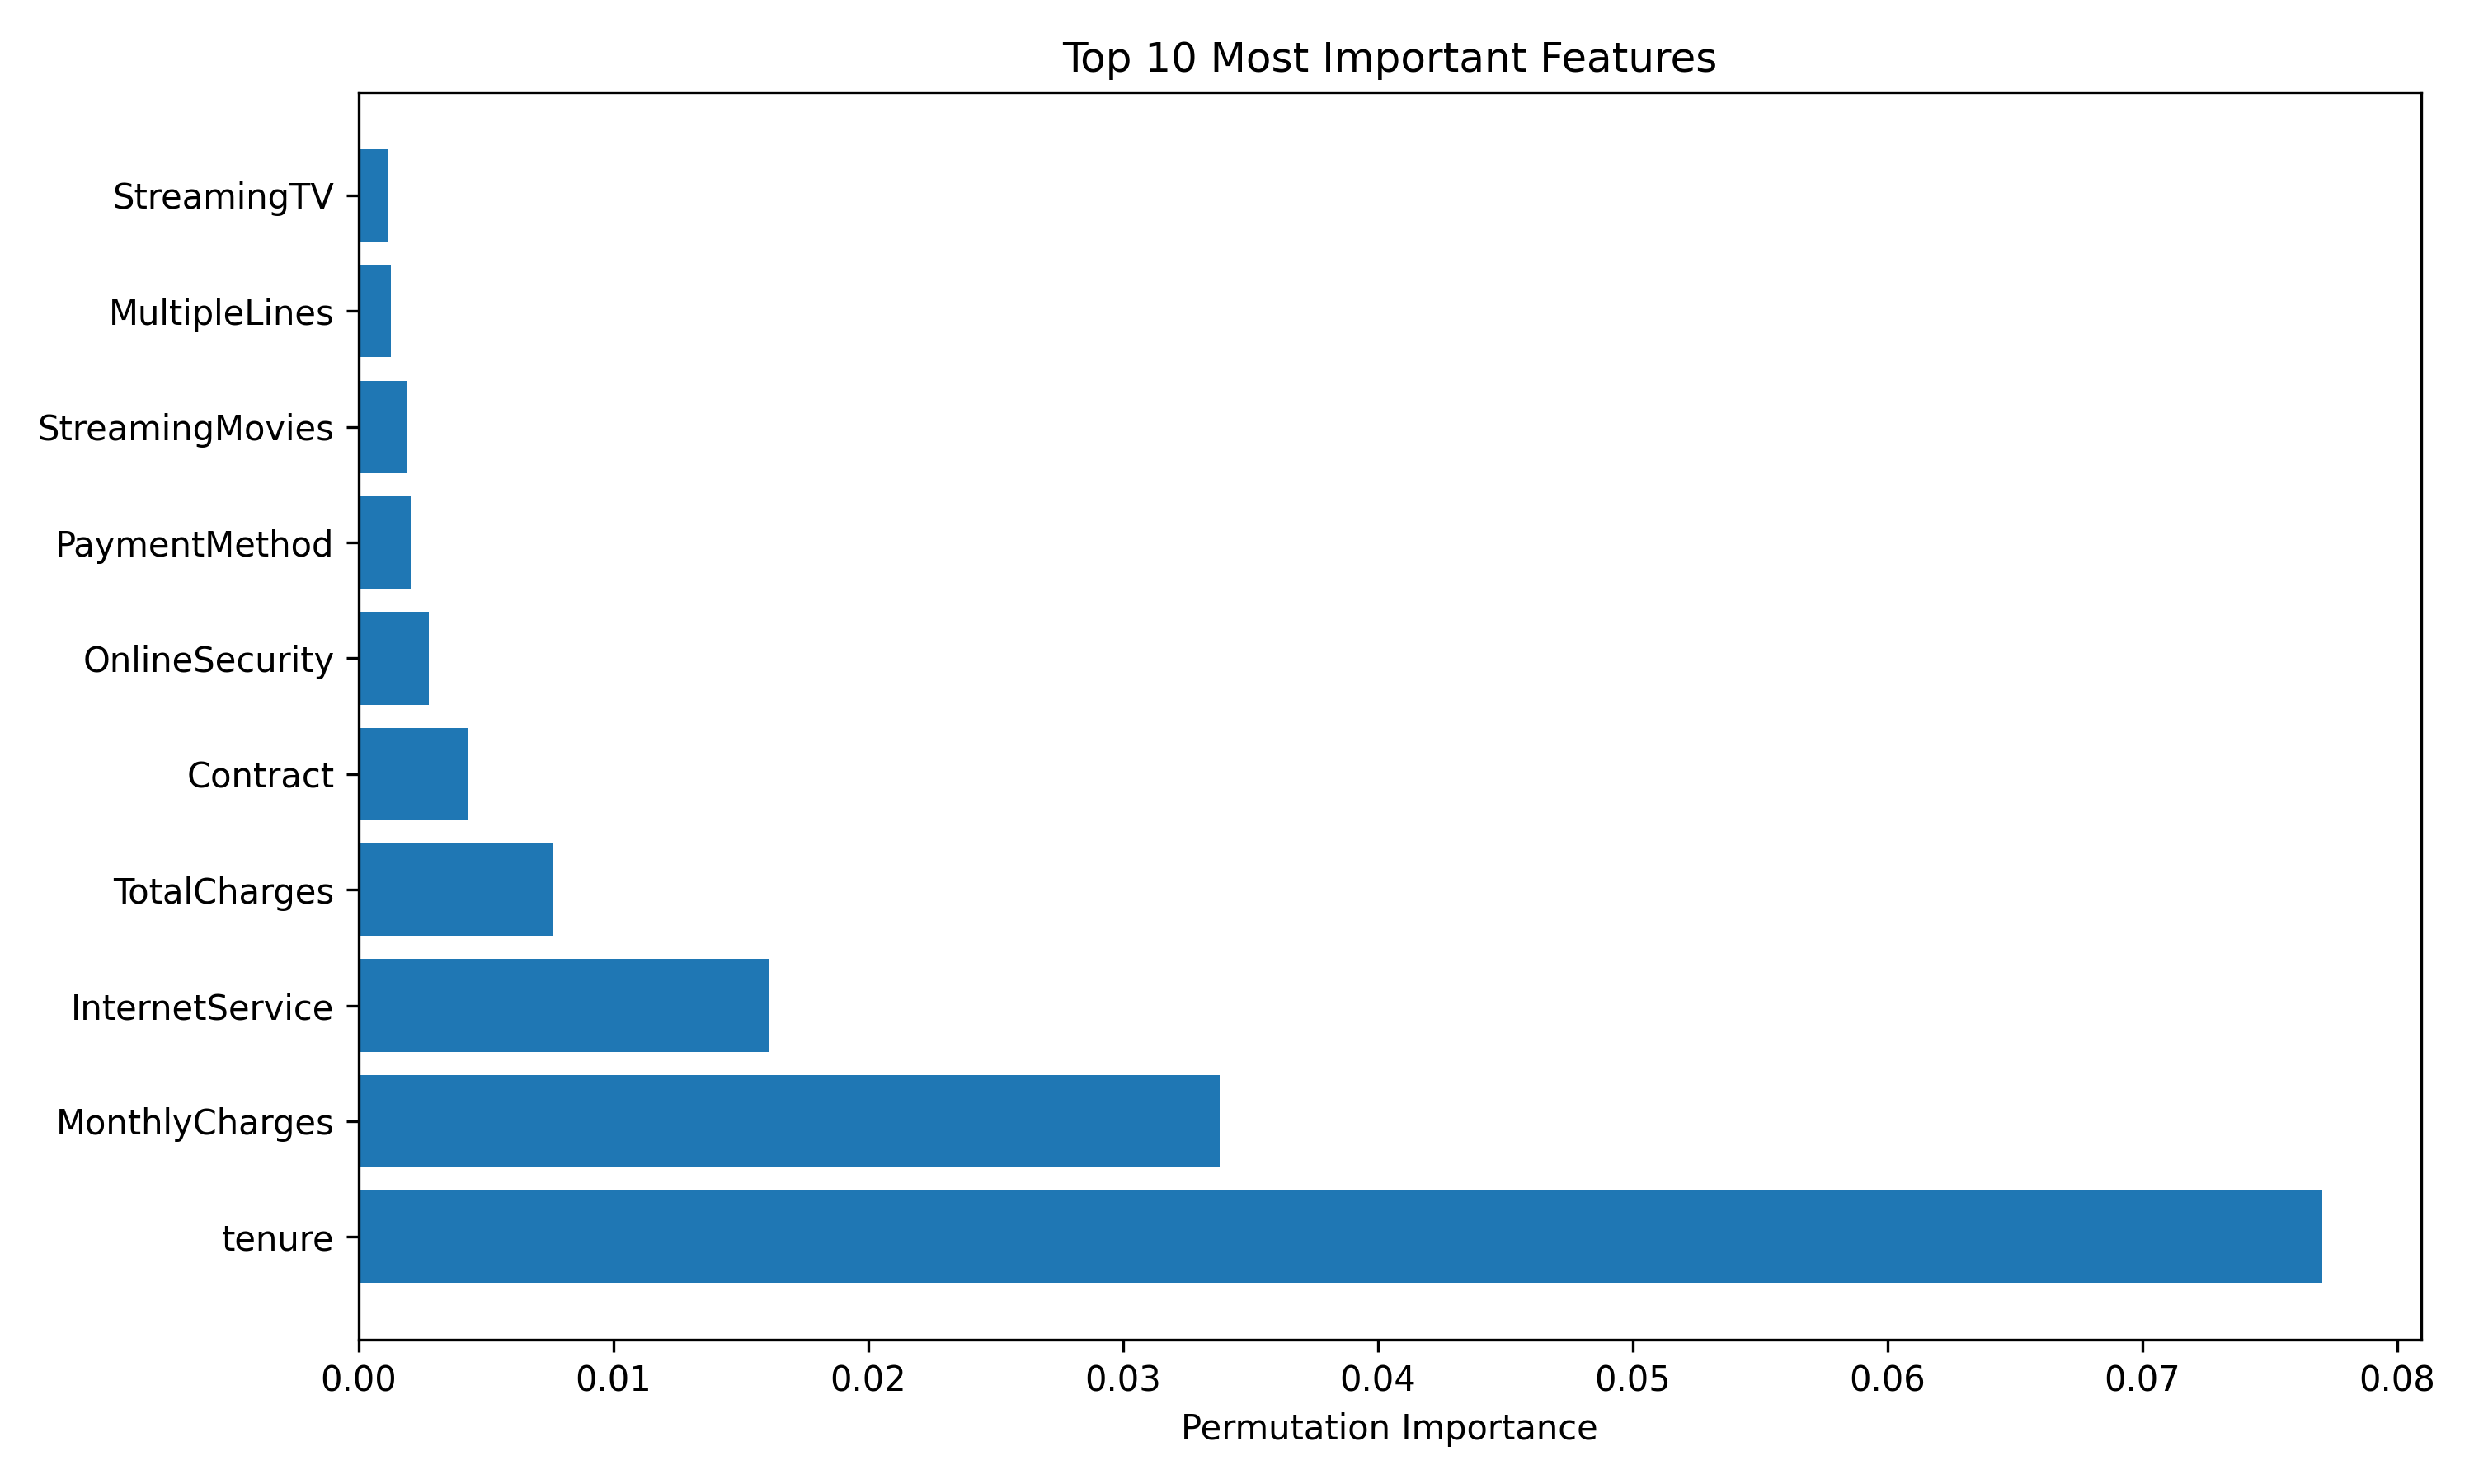

In [8]:
print("Feature Importance:")
Image(filename='../reports/figures/feature_importance.png')

## Rekomendasi Bisnis (3-5)

1. **Fokus pada pelanggan tenure <18 bulan** dengan insentif untuk bertahan melewati tahun pertama.
2. **Konversi pelanggan month-to-month ke kontrak jangka panjang** dengan bundling diskon/add-on.
3. **Tech support wajib untuk pelanggan fiber optic** – bundling gratis selama 6 bulan untuk mengurangi churn.

Lihat laporan lengkap di `../reports/laporan.md` untuk detail lebih.